In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Scikit-learn pour la préparation, la réduction de dimension et le clustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

In [46]:
# Lecture du dataset
df  = pd.read_csv("AB_NYC_2019.csv")

# Data Cleaning and preparation

In [47]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [48]:
# 1 reviews_per_month : if NaN then 0
df['reviews_per_month'].fillna(0, inplace=True)
print(f"Missing values in 'reviews_per_month' filled with 0.")

# 2 Deleting of unused columns
to_drop = ['name', 'id', 'last_review']
df.drop(columns=to_drop, inplace=True)
print("Unused columns: 'name', 'id', 'last_review' deleted.")

# 3 Removing outliers in 'price' using the 99th percentile
price_cap = df['price'].quantile(0.99)
df = df[df['price'] < price_cap]
df = df[df['price'] > 0]
print(f"Outliers in 'price' above {price_cap} removed.")

# 4 feature engineering: creating log_price
df['log_price'] = np.log1p(df['price'])
df['log_price'] = df['log_price'].round(2)
print("Feature 'log_price' created using log transformation of 'price'.")

# cleaned df
df_cleaned = df.copy()
print("Data cleaning completed. Cleaned DataFrame is ready for analysis.")

Missing values in 'reviews_per_month' filled with 0.
Unused columns: 'name', 'id', 'last_review' deleted.
Outliers in 'price' above 799.0 removed.
Feature 'log_price' created using log transformation of 'price'.
Data cleaning completed. Cleaned DataFrame is ready for analysis.


# Explanatory data analysis

In [49]:
# 1 general info
print("DataFrame Info:")
df_cleaned.info()

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
Index: 48392 entries, 0 to 48894
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   host_id                         48392 non-null  int64  
 1   host_name                       48371 non-null  object 
 2   neighbourhood_group             48392 non-null  object 
 3   neighbourhood                   48392 non-null  object 
 4   latitude                        48392 non-null  float64
 5   longitude                       48392 non-null  float64
 6   room_type                       48392 non-null  object 
 7   price                           48392 non-null  int64  
 8   minimum_nights                  48392 non-null  int64  
 9   number_of_reviews               48392 non-null  int64  
 10  reviews_per_month               48392 non-null  float64
 11  calculated_host_listings_count  48392 non-null  int64  
 12  availability_365     

In [50]:
# 2 missing values
print("\nMissing percentile Values in Each Column:")
df_cleaned.isnull().sum()/df_cleaned.shape[0] * 100


Missing percentile Values in Each Column:


host_id                           0.000000
host_name                         0.043396
neighbourhood_group               0.000000
neighbourhood                     0.000000
latitude                          0.000000
longitude                         0.000000
room_type                         0.000000
price                             0.000000
minimum_nights                    0.000000
number_of_reviews                 0.000000
reviews_per_month                 0.000000
calculated_host_listings_count    0.000000
availability_365                  0.000000
log_price                         0.000000
dtype: float64

In [51]:
# 3 statistical summary
print("\nStatistical Summary of Numerical Columns:")
df_cleaned.describe()


Statistical Summary of Numerical Columns:


,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,log_price
count,4.839200e+04,48392.000000,48392.000000,48392.000000,48392.000000,48392.000000,48392.000000,48392.000000,48392.000000,48392.000000
mean,6.757340e+07,40.728902,-73.951924,137.329145,6.980472,23.419449,1.096973,7.180567,112.014507,4.712931
std,7.856254e+07,0.054628,0.046170,103.012234,20.296888,44.706687,1.601271,33.100476,131.208717,0.646657
min,2.438000e+03,40.499790,-74.244420,10.000000,1.000000,0.000000,0.000000,1.000000,0.000000,2.400000
25%,7.820478e+06,40.689940,-73.982843,69.000000,1.000000,1.000000,0.040000,1.000000,0.000000,4.250000
50%,3.080866e+07,40.722885,-73.955480,105.000000,3.000000,5.000000,0.380000,1.000000,44.000000,4.660000
75%,1.074344e+08,40.763160,-73.935950,175.000000,5.000000,24.000000,1.600000,2.000000,224.000000,5.170000
max,2.743213e+08,40.913060,-73.712990,795.000000,1250.000000,629.000000,58.500000,327.000000,365.000000,6.680000


In [52]:
df.describe(exclude=['number'])

,host_name,neighbourhood_group,neighbourhood,room_type
count,48371,48392,48392,48392
unique,11360,5,220,3
top,Michael,Manhattan,Williamsburg,Entire home/apt
freq,411,21294,3904,25011


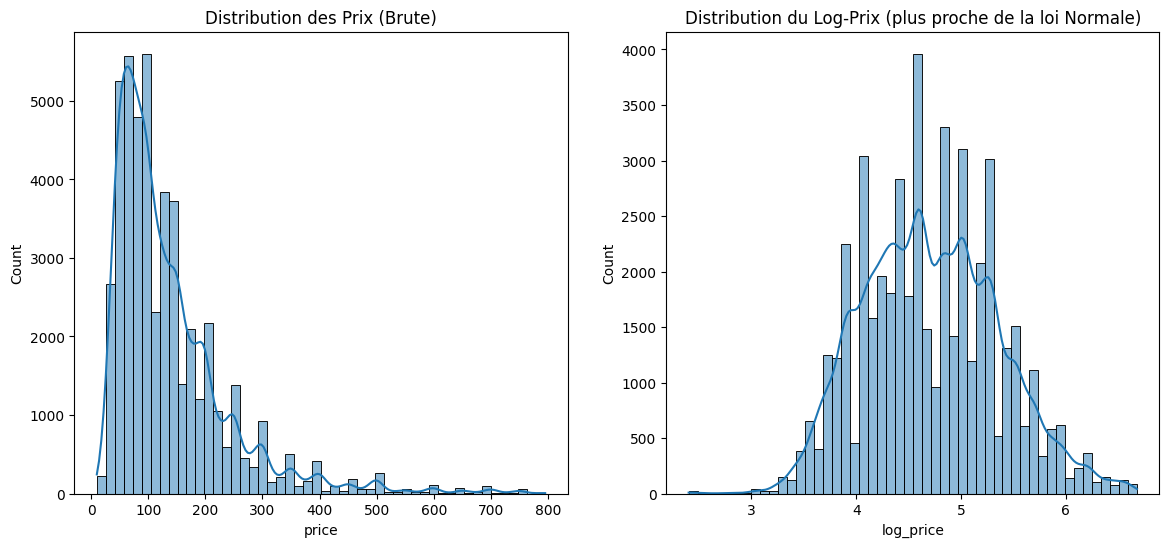

In [53]:
# 1 price distribution
plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
sns.histplot(df_cleaned['price'], kde=True, bins=50)
plt.title('Distribution des Prix (Brute)')
# 2 log_price distribution
plt.subplot(1, 2, 2)
sns.histplot(df_cleaned['log_price'], kde=True, bins=50)
plt.title('Distribution du Log-Prix (plus proche de la loi Normale)')
plt.show()

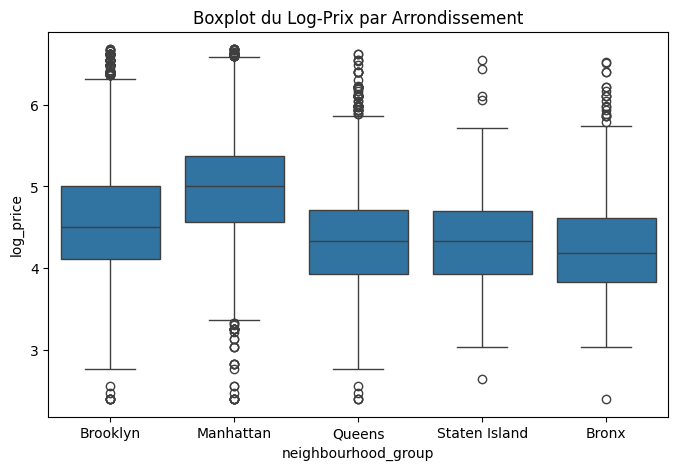

In [54]:
#  Bivariate Analysis: Boxplot of log_price by neighbourhood_group
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_cleaned, x='neighbourhood_group', y='log_price')
plt.title('Boxplot du Log-Prix par Arrondissement')
plt.show()

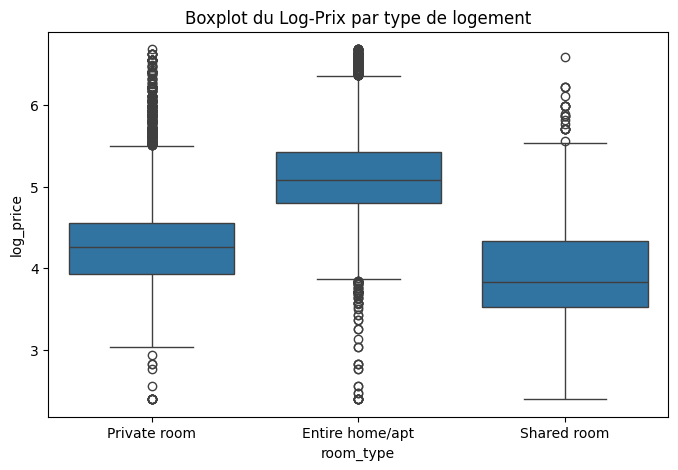

In [55]:
# Bivariate Analysis: Boxplot of log_price by room_type
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_cleaned, x='room_type', y='log_price')
plt.title('Boxplot du Log-Prix par type de logement')
plt.show()

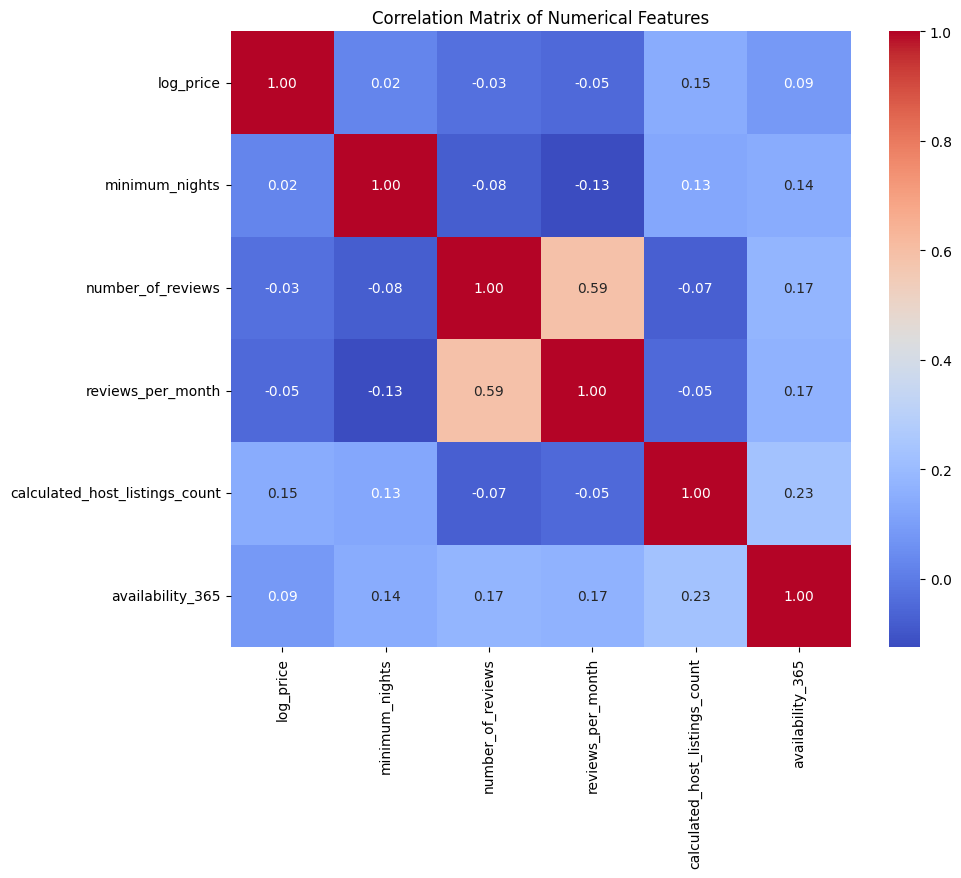

In [56]:
# collation matrix
numerical_cols = ['log_price', 'minimum_nights', 'number_of_reviews', 
                  'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
corr_matrix = df_cleaned[numerical_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()

In [57]:
# Hypothesis testing: ANOVA test for log_price across neighbourhood_group
# 1 ANOVA test
groups = [group['log_price'].values for name, group in df_cleaned.groupby('neighbourhood_group')]
f_stat, p_value = stats.f_oneway(*groups)
print(f"ANOVA test results for log_price across neighbourhood_group: F-statistic = {f_stat}, p-value = {p_value}")
if p_value < 0.05:
	print("Reject the null hypothesis: Significant differences exist between groups.")	
else:
	print("Fail to reject the null hypothesis: No significant differences between groups.")
 
 # 2 t-test for log_price between two room_types: 'Shared room' and 'Private room'
entire_home = df_cleaned[df_cleaned['room_type'] == 'Shared room']['log_price']
private_room = df_cleaned[df_cleaned['room_type'] == 'Private room']['log_price']
t_stat, p_value = stats.ttest_ind(entire_home, private_room, equal_var=False)
print(f"T-test results for log_price between 'Shared room' and 'Private room': T-statistic = {t_stat}, p-value = {p_value}")
if p_value < 0.05:		
	print("Reject the null hypothesis: Significant difference in log_price between the two room types.")	
else:
	print("Fail to reject the null hypothesis: No significant difference in log_price between the two room types.")

# 3 Chi-squared test for independence between neighbourhood_group and room_type
contingency_table = pd.crosstab(df_cleaned['neighbourhood_group'], df_cleaned['room_type'])
chi2_stat, p_value, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-squared test results between neighbourhood_group and room_type: Chi2-statistic = {chi2_stat}, p-value = {p_value}")
if p_value < 0.05:
	print("Reject the null hypothesis: Variables are dependent.")	
else:
	print("Fail to reject the null hypothesis: Variables are independent.")

ANOVA test results for log_price across neighbourhood_group: F-statistic = 1914.1349776549484, p-value = 0.0
Reject the null hypothesis: Significant differences exist between groups.
T-test results for log_price between 'Shared room' and 'Private room': T-statistic = -19.06000319835885, p-value = 3.826822930946871e-71
Reject the null hypothesis: Significant difference in log_price between the two room types.
Chi-squared test results between neighbourhood_group and room_type: Chi2-statistic = 1496.6493493852556, p-value = 0.0
Reject the null hypothesis: Variables are dependent.


In [58]:
# Post-hoc analysis: Tukey's HSD test for neighbourhood_group 
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(df_cleaned['log_price'], df_cleaned['neighbourhood_group'])
print(tukey)

# Post-hoc analysis: Tukey's HSD test for room_type 
tukey_room = pairwise_tukeyhsd(df_cleaned['log_price'], df_cleaned['room_type'])
print(tukey_room)	

     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1      group2    meandiff p-adj   lower   upper  reject
--------------------------------------------------------------
    Bronx      Brooklyn   0.3128    0.0  0.2617  0.3638   True
    Bronx     Manhattan   0.7182    0.0  0.6673  0.7692   True
    Bronx        Queens    0.125    0.0  0.0707  0.1793   True
    Bronx Staten Island    0.103 0.0359  0.0043  0.2018   True
 Brooklyn     Manhattan   0.4055    0.0  0.3893  0.4216   True
 Brooklyn        Queens  -0.1878    0.0 -0.2125 -0.1631   True
 Brooklyn Staten Island  -0.2098    0.0 -0.2959 -0.1236   True
Manhattan        Queens  -0.5933    0.0 -0.6178 -0.5687   True
Manhattan Staten Island  -0.6152    0.0 -0.7013 -0.5291   True
   Queens Staten Island   -0.022 0.9608   -0.11  0.0661  False
--------------------------------------------------------------
       Multiple Comparison of Means - Tukey HSD, FWER=0.05        
     group1        group2    meandiff p-adj  lower 

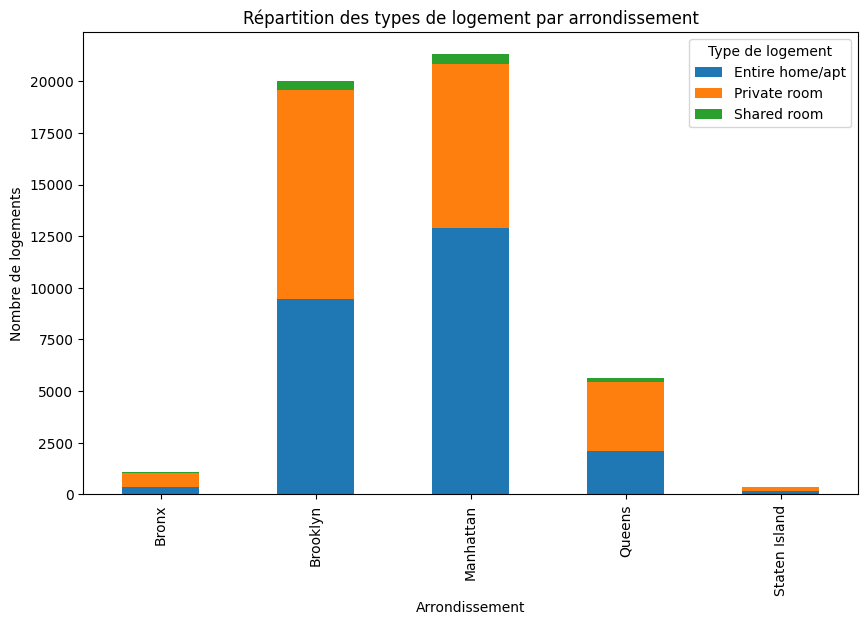

In [59]:
df_room_type_neighbourhood = df.room_type.groupby(df.neighbourhood_group).value_counts().unstack()
df_room_type_neighbourhood.plot(kind='bar', stacked=True, figsize=(10,6))
plt.title('Répartition des types de logement par arrondissement')
plt.xlabel('Arrondissement')
plt.ylabel('Nombre de logements')
plt.legend(title='Type de logement')
plt.show()

# Dimensio reduction

Reduction and visualisation

Explained variance ratio: [0.28198367 0.23336225]


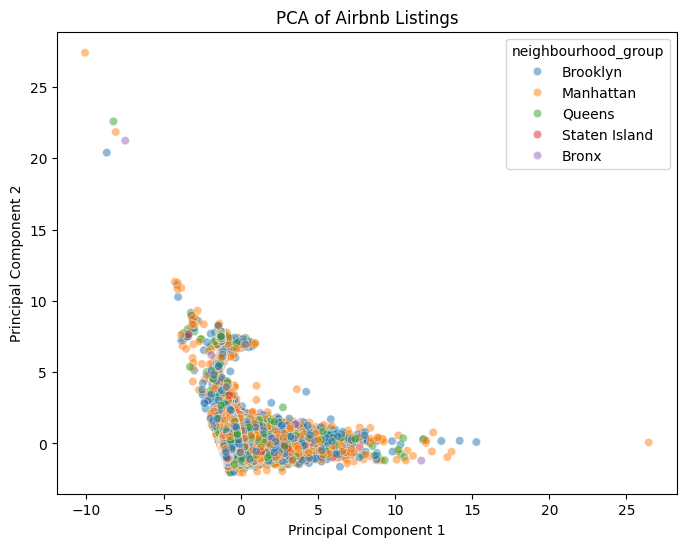

In [60]:
# 1 data preparation for PCA
PCA_features = ['log_price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
df_pca = df_cleaned[PCA_features]

# 2 Standardization crucial for PCA transformation
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_pca)

# 3 PCA transformation
pca = PCA(n_components=2)
df_pca = pca.fit_transform(df_scaled)

# 3 explained variance by the first 2 components
explained_var_ratio = pca.explained_variance_ratio_
print(f"Explained variance ratio: {explained_var_ratio}")

# 4 visualisation on the first two components
df_pca_final = pd.DataFrame(df_pca, columns=["PC1", "PC2"])

plt.figure(figsize=(8,6))
sns.scatterplot(x='PC1', y='PC2', data=df_pca_final, alpha=0.5, hue=df_cleaned['neighbourhood_group'])
plt.title('PCA of Airbnb Listings')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

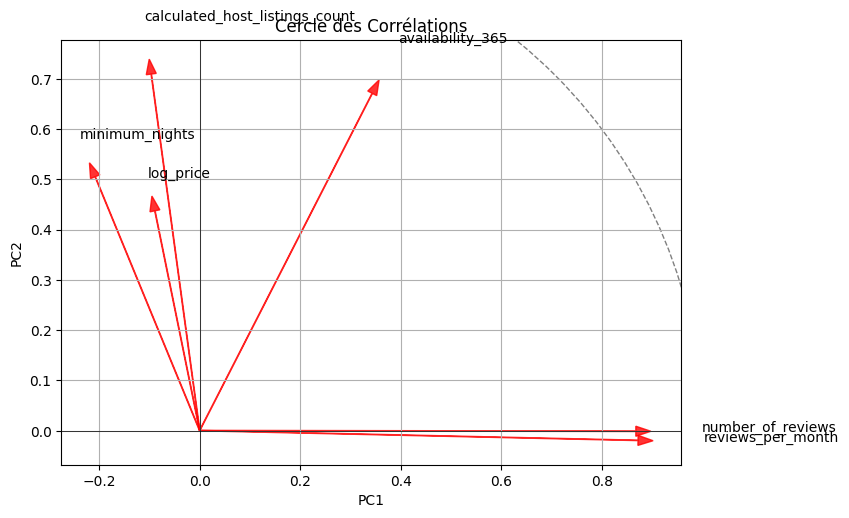

In [61]:
# PCA Circle of Correlations

loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

fig, ax = plt.subplots(figsize=(8, 8))
for i, feature in enumerate(PCA_features):
    ax.arrow(0, 0, loadings[i,0], loadings[i,1], color='r', alpha=0.8, head_width=0.02)
    ax.text(loadings[i,0]*1.15, loadings[i,1]*1.15, feature, color='black')
circle = plt.Circle((0,0), 1, color='gray', fill=False, linestyle='--')
ax.add_artist(circle)
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('Cercle des Corrélations')
ax.set_aspect('equal', adjustable='box')
ax.grid(True)
plt.show()

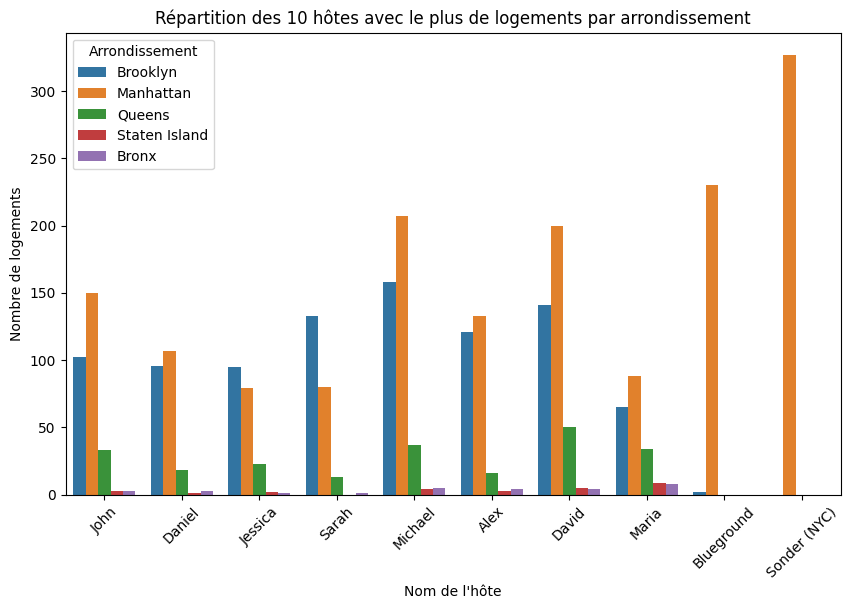

In [69]:
# repartition des top hôtes par arrondissement
top_hosts = df_cleaned['host_name'].value_counts().head(10).index
df_top_hosts = df[df['host_name'].isin(top_hosts)]
plt.figure(figsize=(10,6))
sns.countplot(data=df_top_hosts, x='host_name', hue='neighbourhood_group')
plt.title('Répartition des 10 hôtes avec le plus de logements par arrondissement')
plt.xlabel('Nom de l\'hôte')
plt.xticks(rotation=45)
plt.ylabel('Nombre de logements')
plt.legend(title='Arrondissement')
plt.show()

In [88]:
df_cleaned[df_cleaned['availability_365']==365][df_cleaned['minimum_nights'] < 30]

,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,log_price
0,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365,5.01
2,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,0.00,1,365,5.02
38,45445,Harriet,Brooklyn,Flatbush,40.63702,-73.96327,Private room,150,1,0,0.00,1,365,5.02
97,82685,Elliott,Manhattan,Harlem,40.82803,-73.94731,Private room,89,1,1,0.11,1,365,4.50
139,116599,Sahr,Brooklyn,Clinton Hill,40.68630,-73.96765,Private room,135,4,84,0.77,3,365,4.91
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48698,217557021,Jas,Manhattan,Hell's Kitchen,40.76170,-73.99815,Private room,180,3,0,0.00,1,365,5.20
48844,115491896,Will,Manhattan,West Village,40.73620,-74.00827,Entire home/apt,205,1,0,0.00,1,365,5.33
48868,261338177,Diana,Brooklyn,Gravesend,40.59118,-73.97119,Shared room,25,7,0,0.00,6,365,3.26
48880,208514239,Melki,Brooklyn,Williamsburg,40.71232,-73.94220,Entire home/apt,120,1,0,0.00,3,365,4.80


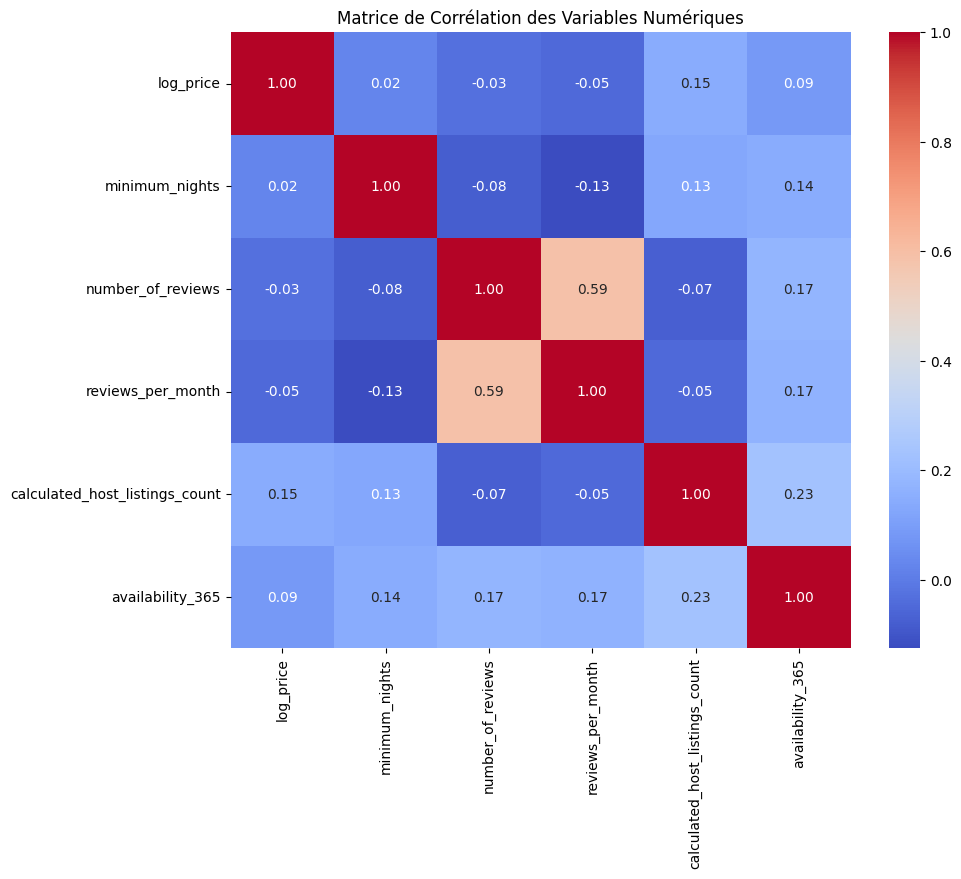

In [63]:
# 3. Matrice de corrélation des variables quantitatives
numerical_cols = ['log_price', 'minimum_nights', 'number_of_reviews', 
                  'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
corr_matrix = df_cleaned[numerical_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matrice de Corrélation des Variables Numériques')
plt.show()

In [64]:
# 4. Tests d'Hypothèses
# Test 1: T-test de Student - Le prix moyen à Manhattan est-il différent de celui de Brooklyn ?
manhattan_prices = df_cleaned[df_cleaned['neighbourhood_group'] == 'Queens']['log_price']
brooklyn_prices = df_cleaned[df_cleaned['neighbourhood_group'] == 'Brooklyn']['log_price']
t_stat, p_value = stats.ttest_ind(manhattan_prices, brooklyn_prices, equal_var=False)
print(f"--- T-test (Manhattan vs Brooklyn) ---")
print(f"P-valeur: {p_value:.5f}")
if p_value < 0.05:
    print("Conclusion : On rejette l'hypothèse nulle. Les prix moyens sont significativement différents.")
else:
    print("Conclusion : On ne peut pas rejeter l'hypothèse nulle.")

--- T-test (Manhattan vs Brooklyn) ---
P-valeur: 0.00000
Conclusion : On rejette l'hypothèse nulle. Les prix moyens sont significativement différents.


In [ ]:
# Test 2: Test du Chi-carré - Y a-t-il une dépendance entre le type de chambre et l'arrondissement ?
contingency_table = pd.crosstab(df_cleaned['neighbourhood_group'], df_cleaned['room_type'])
chi2, p_value, _, _ = stats.chi2_contingency(contingency_table)
print(f"\n--- Test du Chi-carré (Arrondissement vs Type de chambre) ---")
print(f"P-valeur: {p_value:.5f}")
if p_value < 0.05:
    print("Conclusion : On rejette l'hypothèse nulle. Il y a une association significative entre les variables.")
else:
    print("Conclusion : On ne peut pas rejeter l'hypothèse nulle.")
display(contingency_table)


--- Test du Chi-carré (Arrondissement vs Type de chambre) ---
P-valeur: 0.00000
Conclusion : On rejette l'hypothèse nulle. Il y a une association significative entre les variables.


In [66]:
contingency_table

room_type,Entire home/apt,Private room,Shared room
neighbourhood_group,,,
Bronx,378,650,59
Brooklyn,9480,10101,411
Manhattan,12894,7923,477
Queens,2087,3368,195
Staten Island,172,188,9
